# Analisis Telemetri Lintas Domain & Eksplorasi Data (EDA)
**Dataset:** `data/telemetry_dataset_10min_complete.csv` (4.500 sampel, 40 kolom, 8 skenario eksperimen)  
**Lingkup:** 5G O-RAN Multi-Slice (Radio gNB, Core UPF, & 3GPP NWDAF AnLF)


## Tahap 1: Pemuatan Data & Demarkasi Kolom (Data Ingestion & Demarcation)
- **Tujuan:** Memuat dataset telemetri multi-domain dan memetakan taksonomi kolom sesuai peran fungsional pada arsitektur sistem.
- **Target:** Dataset 4.500 sampel termuat tanpa error dan 40 kolom terklasifikasi ke dalam 5 grup taksonomi (Metadata, SLA Probe, RAN, Core UPF, dan 3GPP NWDAF).


In [1]:
# 1. Import library analisis dan konfigurasi visualisasi
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 120

DATASET_PATH = os.path.join('..', 'data', 'telemetry_dataset_10min_complete.csv')
if not os.path.exists(DATASET_PATH):
    DATASET_PATH = os.path.join('data', 'telemetry_dataset_10min_complete.csv')

df = pd.read_csv(DATASET_PATH)
print(f'Dataset berhasil dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom')


Dataset berhasil dimuat: 4,500 baris x 40 kolom


In [2]:
# 2. Pengelompokan taksonomi kolom resmi
METADATA_COLS = [
    'timestamp_utc', 'elapsed_sec', 'run_id', 'scrape_ok', 'scrape_latency_ms',
    'event_phase_id', 'event_scenario', 'event_domain', 'event_component',
    'rapp_diagnosed_bottleneck', 'rapp_confidence'
]

SLA_PROBE_COLS = [
    'e2e_slice1_tput_mbps', 'e2e_slice1_jitter_ms', 'e2e_slice1_rtt_ms', 'e2e_slice1_loss_pct',
    'e2e_slice2_rtt_ms', 'e2e_slice2_loss_pct', 'e2e_probe_freshness'
]

INFRA_RAN_COLS = [
    'ran_prb_cell1', 'ran_prb_cell2', 'ran_mcs_cell1', 'ran_mcs_cell2',
    'ran_bler_cell1', 'ran_bler_cell2', 'ran_snr_cell1', 'ran_snr_cell2'
]

INFRA_CORE_COLS = [
    'estimated_load_embb', 'estimated_load_urllc',
    'upf_backlog_bytes_embb', 'upf_backlog_bytes_urllc',
    'upf_drops_embb', 'upf_drops_urllc'
]

NWDAF_COLS = [
    'nwdaf_load_embb', 'nwdaf_load_urllc', 'nwdaf_comm_ul_bytes', 'nwdaf_comm_dl_bytes',
    'nwdaf_comm_duration_sec', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_freshness', 'nwdaf_api_status'
]

classified_total = len(METADATA_COLS) + len(SLA_PROBE_COLS) + len(INFRA_RAN_COLS) + len(INFRA_CORE_COLS) + len(NWDAF_COLS)
print(f'Total Kolom Terklasifikasi: {classified_total} / {df.shape[1]} kolom')


Total Kolom Terklasifikasi: 40 / 40 kolom


## Tahap 2: Pembersihan Data & Audit Kualitas (Data Cleansing & Quality Audit)
- **Tujuan:** Mendeteksi missing values (`NaN`), mengidentifikasi fitur bervariansi nol (konstan), dan memverifikasi integritas scraping pada setiap run eksperimen.
- **Target:** Matriks kualitas data 40 fitur dan ringkasan operasional 8 run eksperimen; fitur tidak informatif teridentifikasi untuk dieksklusi secara objektif.


In [3]:
# 1. Audit kelengkapan dan variansi per kolom
audit_rows = []
for col in df.columns:
    total_count = len(df[col])
    nan_count = int(df[col].isnull().sum())
    valid_count = total_count - nan_count
    pct_valid = round((valid_count / total_count) * 100.0, 1)
    
    is_numeric = pd.api.types.is_numeric_dtype(df[col])
    num_unique = df[col].nunique(dropna=True)
    is_constant = (num_unique <= 1)
    
    val_min = round(float(df[col].min()), 2) if is_numeric and valid_count > 0 else 'N/A'
    val_max = round(float(df[col].max()), 2) if is_numeric and valid_count > 0 else 'N/A'
    
    audit_rows.append({
        'Kolom': col,
        'Tipe': 'Numeric' if is_numeric else 'String',
        'Valid': valid_count,
        'NaN': nan_count,
        '% Valid': f'{pct_valid}%',
        'Unique': num_unique,
        'Status Variasi': '100% NaN' if valid_count == 0 else ('Konstan' if is_constant else 'Bervariasi'),
        'Min': str(val_min),
        'Max': str(val_max)
    })

df_audit = pd.DataFrame(audit_rows)
pd.set_option('display.max_rows', 45)
display(df_audit)

cols_all_nan = df_audit[df_audit['Status Variasi'] == '100% NaN']['Kolom'].tolist()
cols_constant = df_audit[df_audit['Status Variasi'] == 'Konstan']['Kolom'].tolist()

print(f'Kolom 100% NaN ({len(cols_all_nan)}): {cols_all_nan}')
print(f'Kolom Konstan / Varians Nol ({len(cols_constant)}): {cols_constant}')


Kolom 100% NaN (3): ['e2e_slice1_jitter_ms', 'nwdaf_load_embb', 'nwdaf_load_urllc']
Kolom Konstan / Varians Nol (11): ['scrape_ok', 'e2e_probe_freshness', 'nwdaf_api_status', 'upf_backlog_bytes_urllc', 'upf_drops_urllc', 'ran_prb_cell2', 'ran_mcs_cell1', 'ran_bler_cell1', 'ran_bler_cell2', 'rapp_diagnosed_bottleneck', 'rapp_confidence']


,Kolom,Tipe,Valid,NaN,% Valid,Unique,Status Variasi,Min,Max
0,timestamp_utc,String,4500,0,100.0%,4500,Bervariasi,N/A,N/A
1,elapsed_sec,Numeric,4500,0,100.0%,4391,Bervariasi,0.0,599.0
2,run_id,String,4500,0,100.0%,8,Bervariasi,N/A,N/A
3,scrape_ok,Numeric,4500,0,100.0%,1,Konstan,1.0,1.0
4,scrape_latency_ms,Numeric,4500,0,100.0%,1477,Bervariasi,1.57,9.04
5,e2e_slice1_tput_mbps,Numeric,4500,0,100.0%,32,Bervariasi,9.95,81.1
6,e2e_slice1_jitter_ms,Numeric,0,4500,0.0%,0,100% NaN,N/A,N/A
7,e2e_slice1_rtt_ms,Numeric,3300,1200,73.3%,335,Bervariasi,7.08,445.0
8,e2e_slice1_loss_pct,Numeric,4500,0,100.0%,11,Bervariasi,0.0,100.0
9,e2e_slice2_rtt_ms,Numeric,4500,0,100.0%,349,Bervariasi,7.33,139.0


In [4]:
# 2. Rincian integritas scraping dan telemetri per run eksperimen
run_summary = []
for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    dom = grp['event_domain'].iloc[0]
    n_rows = len(grp)
    scrape_ok_pct = round((grp['scrape_ok'].sum() / n_rows) * 100.0, 1)
    s1_outage_pct = round((grp['e2e_slice1_rtt_ms'].isnull().sum() / n_rows) * 100.0, 1)
    s2_rtt_mean = round(float(grp['e2e_slice2_rtt_ms'].mean()), 2)
    s2_loss_mean = round(float(grp['e2e_slice2_loss_pct'].mean()), 1)
    prb_c1_mean = round(float(grp['ran_prb_cell1'].mean()), 1)
    backlog_max = int(grp['upf_backlog_bytes_embb'].max())
    nwdaf_status = int(grp['nwdaf_api_status'].mean())
    
    run_summary.append({
        'Run ID': run_id,
        'Skenario': scen,
        'Domain': dom,
        'Sampel': n_rows,
        'Scrape OK': f'{scrape_ok_pct}%',
        'eMBB Outage': f'{s1_outage_pct}%',
        'URLLC RTT Avg (ms)': s2_rtt_mean,
        'URLLC Loss (%)': f'{s2_loss_mean}%',
        'PRB C1 Avg (%)': f'{prb_c1_mean}%',
        'Backlog Max (B)': f'{backlog_max:,}',
        'NWDAF Status': nwdaf_status
    })

df_run_summary = pd.DataFrame(run_summary)
display(df_run_summary)


,Run ID,Skenario,Domain,Sampel,Scrape OK,eMBB Outage,URLLC RTT Avg (ms),URLLC Loss (%),PRB C1 Avg (%),Backlog Max (B),NWDAF Status
0,EXP_S1_20261019_232208,S1_NORMAL_LIGHT,BASELINE,600,100.0%,0.0%,21.53,0.0%,63.0%,0,1
1,EXP_S2_20261019_234048,S2_NORMAL_HIGH,BASELINE,600,100.0%,0.0%,22.75,0.0%,74.1%,0,1
2,EXP_S3_20261019_235917,S3_RAN_OVERLOAD,RAN,600,100.0%,100.0%,29.37,5.6%,100.0%,0,1
3,EXP_S6_20261020_001105,S6_CORE_QUEUE_TBF,CORE,600,100.0%,0.0%,22.77,0.0%,74.6%,"310,234",1
4,EXP_S9_20261020_084020,S9_JOINT_OVERLOAD,JOINT,600,100.0%,100.0%,30.06,6.0%,100.0%,"310,226",1
5,EXP_S10_A_20261020_091150,S10_A_RELEASE_RAN,CORE,600,100.0%,0.0%,22.77,0.0%,72.7%,"310,218",1
6,EXP_S10_B_20261020_092453,S10_B_RELEASE_CORE,BASELINE,600,100.0%,0.0%,22.96,0.0%,74.7%,0,1
7,EXP_CLEAR_20261020_093812,CLEAR_FAULT,BASELINE,300,100.0%,0.0%,21.27,0.0%,57.8%,0,1


## Tahap 3: Pra-pemrosesan Data & Rekayasa Fitur (Data Preprocessing & Feature Engineering)
- **Tujuan:** Menghitung fitur turunan fisik, memetakan distribusi kelas target, dan mendemarkasi fitur prediktor ($X$) dari probe SLA untuk mencegah kebocoran data (*data leakage*).
- **Target:** Variabel turunan terstandarisasi (`upf_backlog_kb`, delta rate), distribusi kelas target domain terpetakan, dan definisi subset fitur model final.


In [5]:
# 1. Rekayasa fitur turunan
df['upf_backlog_kb'] = df['upf_backlog_bytes_embb'] / 1024.0
df['ran_prb_pct'] = df['ran_prb_cell1'].clip(0.0, 100.0)

# 2. Pemetaan distribusi kelas target domain
target_dist = df['event_domain'].value_counts()
target_pct = df['event_domain'].value_counts(normalize=True) * 100.0
df_class_dist = pd.DataFrame({
    'Jumlah Sampel': target_dist,
    'Proporsi (%)': target_pct.round(2)
})
print('=== DISTRIBUSI KELAS TARGET (event_domain) ===')
display(df_class_dist)

# 3. Demarkasi fitur prediktor (X) vs Target (y)
FEATURE_COLS_FINAL = [
    # Radio Domain
    'ran_prb_cell1', 'ran_snr_cell1',
    # Core UPF Host OAM Domain
    'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb',
    # Core 3GPP NWDAF AnLF Domain
    'nwdaf_comm_ul_bytes', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_duration_sec'
]

print(f'Jumlah Fitur Masukan Final (X): {len(FEATURE_COLS_FINAL)} fitur')
print('Daftar Fitur X:', FEATURE_COLS_FINAL)


=== DISTRIBUSI KELAS TARGET (event_domain) ===
Jumlah Fitur Masukan Final (X): 8 fitur
Daftar Fitur X: ['ran_prb_cell1', 'ran_snr_cell1', 'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb', 'nwdaf_comm_ul_bytes', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_duration_sec']


,Jumlah Sampel,Proporsi (%)
event_domain,,
BASELINE,2100,46.67
CORE,1200,26.67
RAN,600,13.33
JOINT,600,13.33


## Tahap 4: Analisis Data Eksploratif (Exploratory Data Analysis / EDA)
- **Tujuan:** Menganalisis dinamika runtun waktu lintas run, mengisolasi efek kemacetan via pasangan terkendali, dan mengevaluasi dependensi monotonik antar-fitur fisik.
- **Target:** Visualisasi runtun waktu multi-panel dengan sekat run nyata, boxplot pasangan terkendali (S2 vs S6 dan Staged Recovery), serta matriks korelasi Spearman.


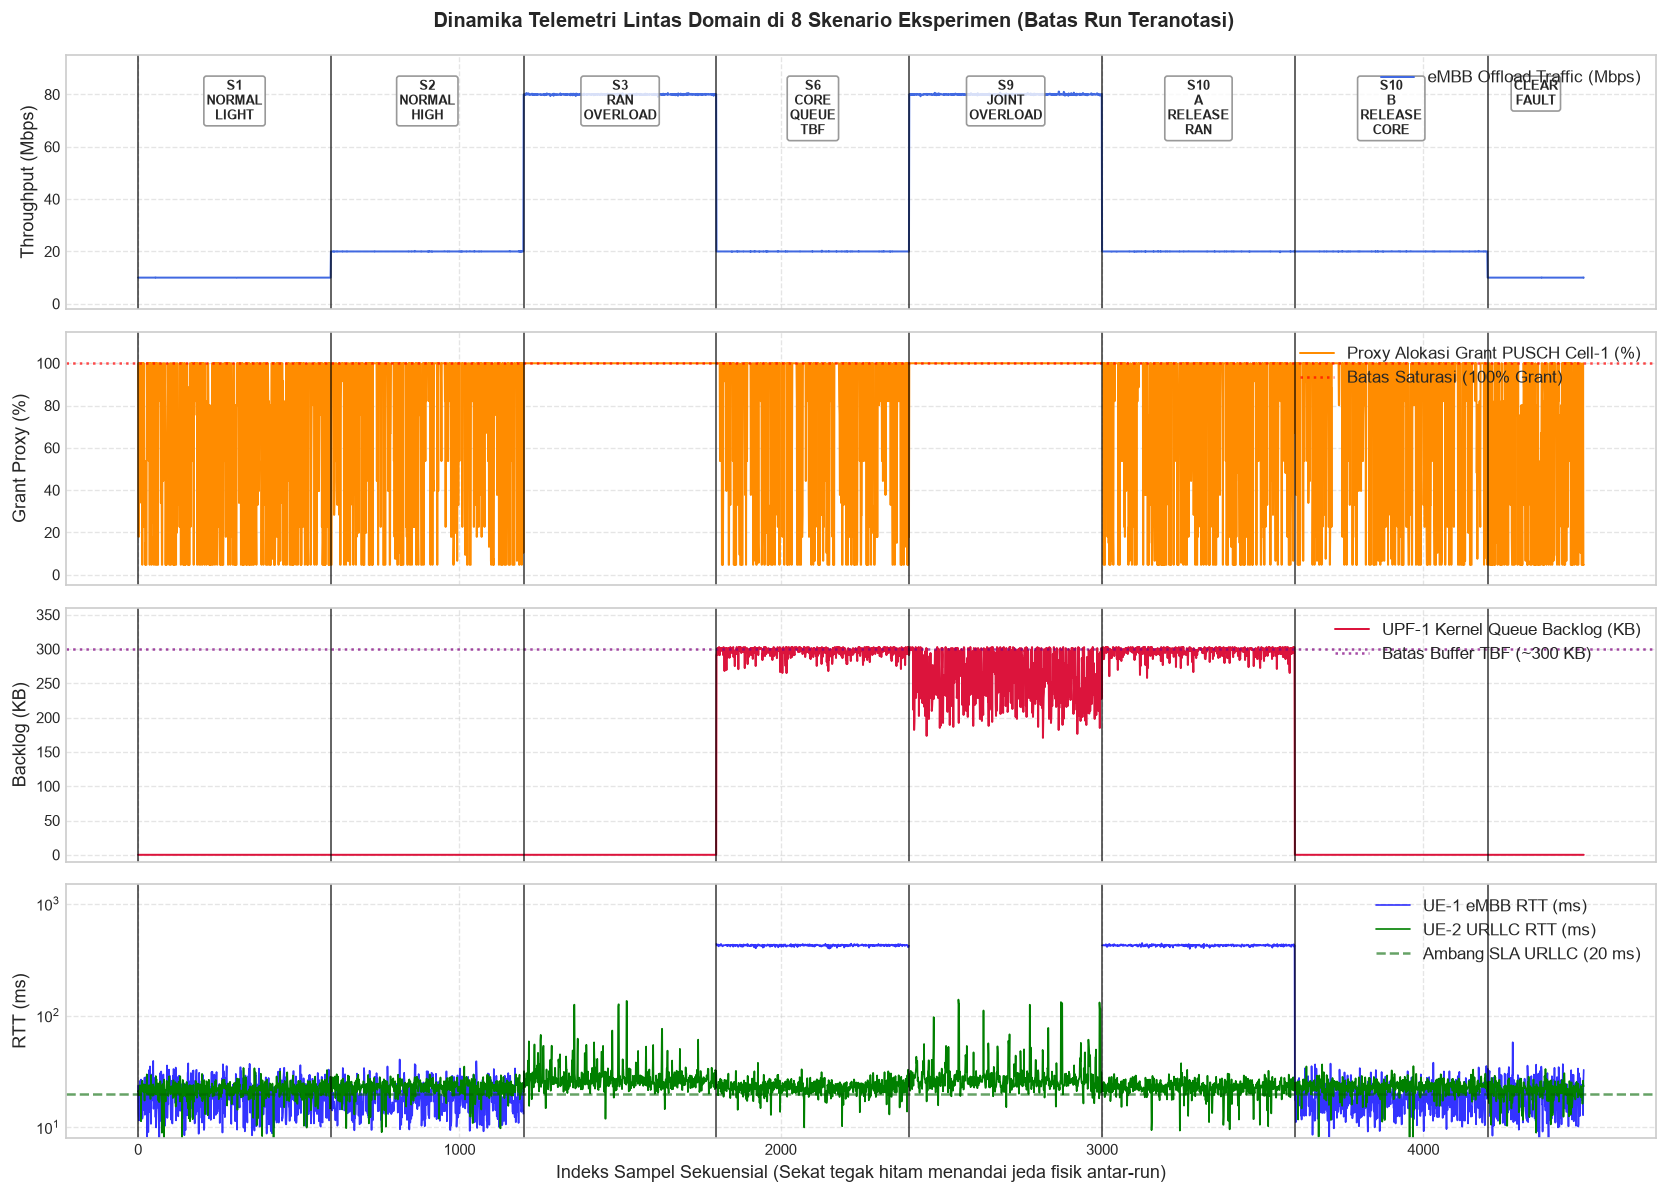

In [6]:
# 1. Dinamika runtun waktu multi-panel (Batas run nyata teranotasi)
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
x_indices = np.arange(len(df))

# Throughput eMBB
axes[0].plot(x_indices, df['e2e_slice1_tput_mbps'], color='royalblue', lw=1.2, label='eMBB Offload Traffic (Mbps)')
axes[0].set_ylabel('Throughput (Mbps)')
axes[0].set_ylim(-2, 95)
axes[0].grid(True, ls='--', alpha=0.5)
axes[0].legend(loc='upper right')

# Proxy Alokasi Grant PUSCH Cell-1
axes[1].plot(x_indices, df['ran_prb_cell1'], color='darkorange', lw=1.2, label='Proxy Alokasi Grant PUSCH Cell-1 (%)')
axes[1].axhline(100.0, color='red', ls=':', alpha=0.7, label='Batas Saturasi (100% Grant)')
axes[1].set_ylabel('Grant Proxy (%)')
axes[1].set_ylim(-5, 115)
axes[1].grid(True, ls='--', alpha=0.5)
axes[1].legend(loc='upper right')

# Kedalaman Antrean UPF (Backlog KB)
axes[2].plot(x_indices, df['upf_backlog_kb'], color='crimson', lw=1.2, label='UPF-1 Kernel Queue Backlog (KB)')
axes[2].axhline(300.0, color='purple', ls=':', alpha=0.7, label='Batas Buffer TBF (~300 KB)')
axes[2].set_ylabel('Backlog (KB)')
axes[2].set_ylim(-10, 360)
axes[2].grid(True, ls='--', alpha=0.5)
axes[2].legend(loc='upper right')

# Latensi Canary RTT UE-1 & UE-2
axes[3].plot(x_indices, df['e2e_slice1_rtt_ms'], color='blue', lw=1.0, alpha=0.8, label='UE-1 eMBB RTT (ms)')
axes[3].plot(x_indices, df['e2e_slice2_rtt_ms'], color='green', lw=1.0, label='UE-2 URLLC RTT (ms)')
axes[3].axhline(20.0, color='darkgreen', ls='--', alpha=0.6, label='Ambang SLA URLLC (20 ms)')
axes[3].set_ylabel('RTT (ms)')
axes[3].set_yscale('log')
axes[3].set_ylim(8, 1500)
axes[3].grid(True, ls='--', alpha=0.5)
axes[3].legend(loc='upper right')

# Garis sekat antar-run eksperimen
current_idx = 0
for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    mid_point = current_idx + len(grp) / 2
    for ax in axes:
        ax.axvline(current_idx, color='black', ls='-', lw=1.2, alpha=0.6)
    label_clean = scen.replace('_', '\n')
    axes[0].text(mid_point, 86, label_clean, ha='center', va='top', fontsize=8, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='gray'))
    current_idx += len(grp)

axes[3].set_xlabel('Indeks Sampel Sekuensial (Sekat tegak hitam menandai jeda fisik antar-run)')
plt.suptitle('Dinamika Telemetri Lintas Domain di 8 Skenario Eksperimen (Batas Run Teranotasi)', y=0.99, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


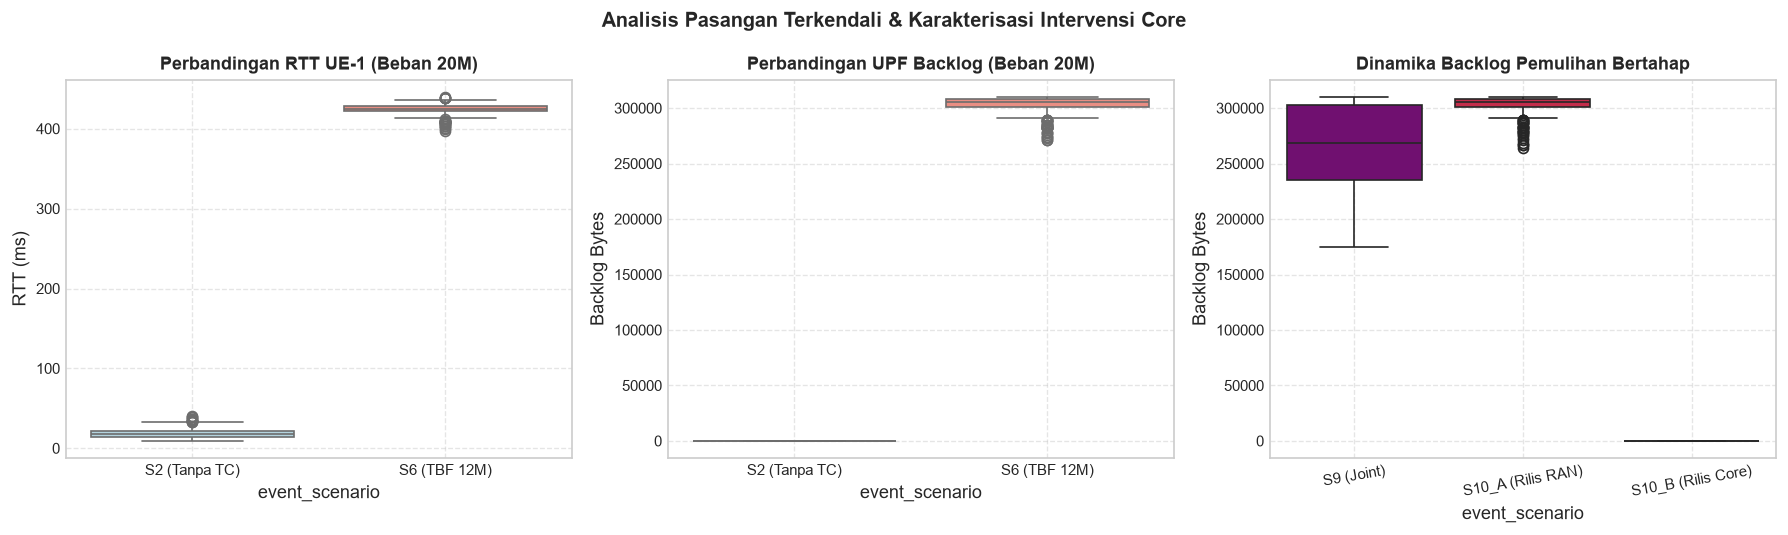

In [7]:
# 2. Evaluasi pasangan terkendali: S2 vs S6 dan Pemulihan Bertahap (Staged Recovery)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# A. Perbandingan RTT UE-1 pada S2 vs S6
df_s2_s6 = df[df['event_scenario'].isin(['S2_NORMAL_HIGH', 'S6_CORE_QUEUE_TBF'])].copy()
sns.boxplot(data=df_s2_s6, x='event_scenario', y='e2e_slice1_rtt_ms', ax=axes[0], palette=['lightblue', 'salmon'])
axes[0].set_title('Perbandingan RTT UE-1 (Beban 20M)', fontweight='bold')
axes[0].set_ylabel('RTT (ms)')
axes[0].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
axes[0].grid(True, ls='--', alpha=0.5)

# B. Perbandingan UPF Backlog pada S2 vs S6
sns.boxplot(data=df_s2_s6, x='event_scenario', y='upf_backlog_bytes_embb', ax=axes[1], palette=['lightblue', 'salmon'])
axes[1].set_title('Perbandingan UPF Backlog (Beban 20M)', fontweight='bold')
axes[1].set_ylabel('Backlog Bytes')
axes[1].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
axes[1].grid(True, ls='--', alpha=0.5)

# C. Rangkaian Pemulihan Bertahap: S9 -> S10_A -> S10_B
df_rec = df[df['event_scenario'].isin(['S9_JOINT_OVERLOAD', 'S10_A_RELEASE_RAN', 'S10_B_RELEASE_CORE'])].copy()
rec_order = ['S9_JOINT_OVERLOAD', 'S10_A_RELEASE_RAN', 'S10_B_RELEASE_CORE']
sns.boxplot(data=df_rec, x='event_scenario', y='upf_backlog_bytes_embb', order=rec_order, ax=axes[2], palette=['purple', 'crimson', 'lightgreen'])
axes[2].set_title('Dinamika Backlog Pemulihan Bertahap', fontweight='bold')
axes[2].set_ylabel('Backlog Bytes')
axes[2].set_xticklabels(['S9 (Joint)', 'S10_A (Rilis RAN)', 'S10_B (Rilis Core)'], rotation=10)
axes[2].grid(True, ls='--', alpha=0.5)

plt.suptitle('Analisis Pasangan Terkendali & Karakterisasi Intervensi Core', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


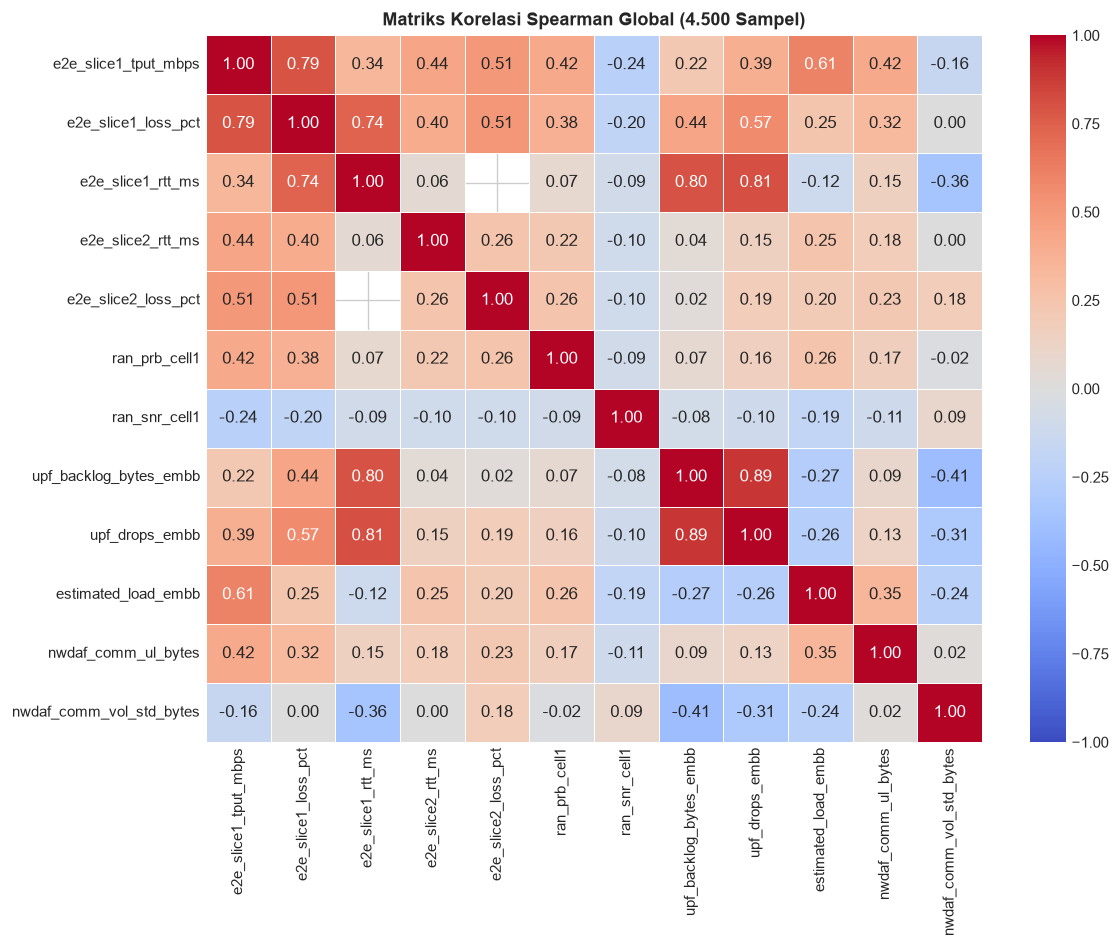

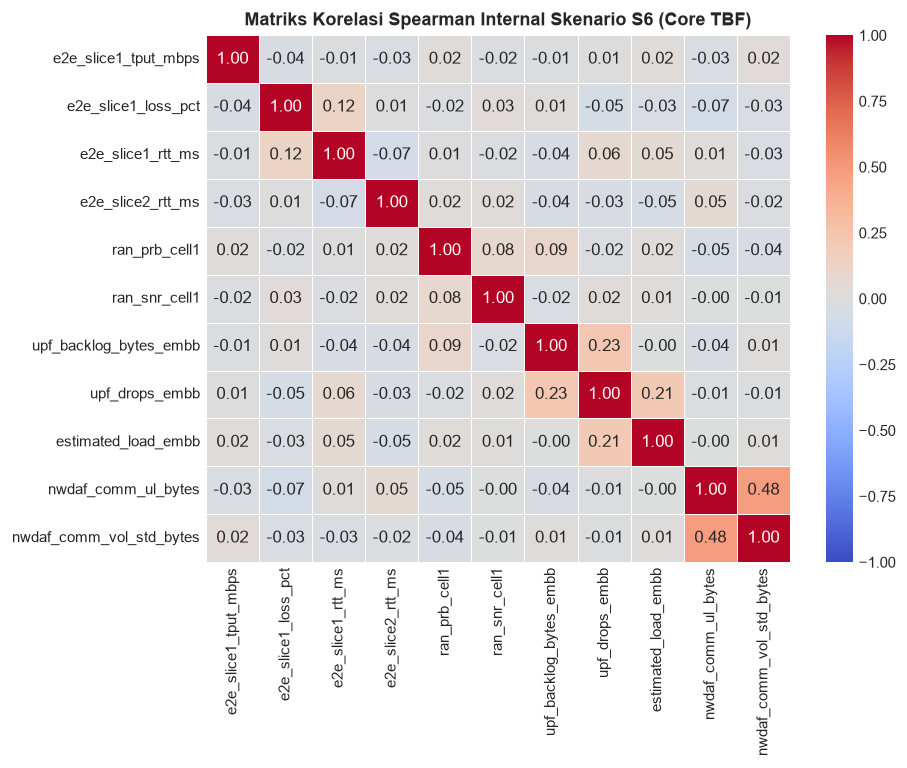

In [8]:
# 3. Analisis matriks korelasi Spearman (Global & Internal S6)
candidate_features = [
    'e2e_slice1_tput_mbps', 'e2e_slice1_loss_pct', 'e2e_slice1_rtt_ms',
    'e2e_slice2_rtt_ms', 'e2e_slice2_loss_pct',
    'ran_prb_cell1', 'ran_snr_cell1',
    'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb',
    'nwdaf_comm_ul_bytes', 'nwdaf_comm_vol_std_bytes'
]

# Korelasi Spearman Global
corr_global = df[candidate_features].corr(method='spearman')
plt.figure(figsize=(10, 8))
sns.heatmap(corr_global, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.0, vmax=1.0, linewidths=0.5)
plt.title('Matriks Korelasi Spearman Global (4.500 Sampel)', fontweight='bold')
plt.tight_layout()
plt.show()

# Korelasi Spearman Internal Skenario Core Bottleneck (S6)
df_s6 = df[df['event_scenario'] == 'S6_CORE_QUEUE_TBF'][candidate_features].dropna(axis=1, how='all')
varying_s6 = [c for c in df_s6.columns if df_s6[c].nunique() > 1]
corr_s6 = df_s6[varying_s6].corr(method='spearman')
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_s6, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.0, vmax=1.0, linewidths=0.5)
plt.title('Matriks Korelasi Spearman Internal Skenario S6 (Core TBF)', fontweight='bold')
plt.tight_layout()
plt.show()


## Tahap 5: Uji Keterpisahan Fitur & Kesiapan Model (Feature Separability & Model Readiness)
- **Tujuan:** Menguji daya pisah fitur fisik (RAN vs Core) terhadap 4 target kelas domain gangguan dan memvalidasi kebutuhan observabilitas lintas domain.
- **Target:** Bukti empiris keterpisahan fitur dan pedoman spesifikasi input/target untuk implementasi model machine learning pada `02_compare_models.ipynb`.


=== RINGKASAN TEMUAN SEPARABILITAS FITUR ===
1. ran_prb_cell1 jenuh pada ~100% di kelas RAN dan JOINT -> tidak dapat membedakan RAN vs JOINT secara mandiri.
2. upf_backlog_bytes jenuh pada ~310 KB di kelas CORE dan JOINT -> tidak dapat membedakan CORE vs JOINT secara mandiri.
3. Kesimpulan: Diperlukan vektor observabilitas lintas domain [PRB, Backlog, NWDAF] untuk klasifikasi unik 4 kelas.


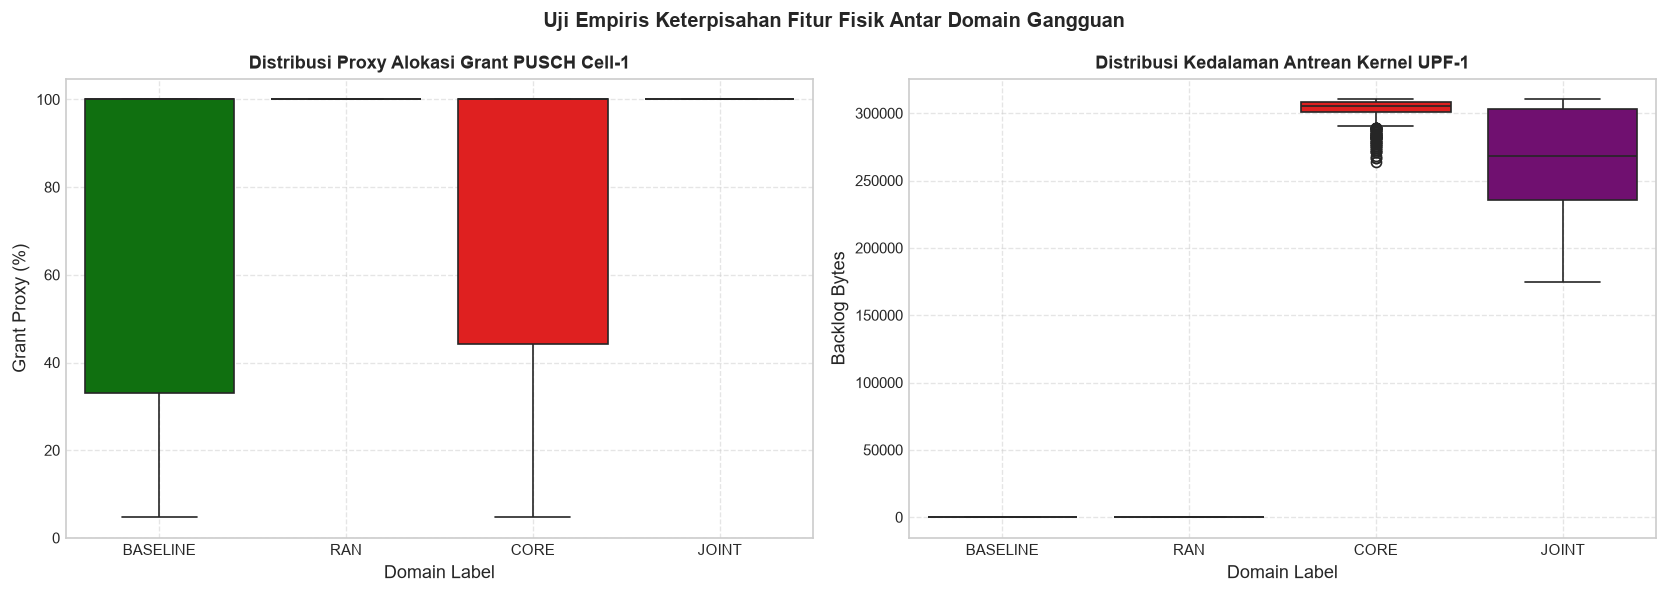

In [9]:
# 1. Uji separabilitas empiris fitur fisik per domain
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
domain_order = ['BASELINE', 'RAN', 'CORE', 'JOINT']
palette = {'BASELINE': 'green', 'RAN': 'orange', 'CORE': 'red', 'JOINT': 'purple'}

# Distribusi PRB C1 per Domain
sns.boxplot(data=df, x='event_domain', y='ran_prb_cell1', order=domain_order, ax=axes[0], palette=palette)
axes[0].set_title('Distribusi Proxy Alokasi Grant PUSCH Cell-1', fontweight='bold')
axes[0].set_xlabel('Domain Label')
axes[0].set_ylabel('Grant Proxy (%)')
axes[0].grid(True, ls='--', alpha=0.5)

# Distribusi UPF Backlog per Domain
sns.boxplot(data=df, x='event_domain', y='upf_backlog_bytes_embb', order=domain_order, ax=axes[1], palette=palette)
axes[1].set_title('Distribusi Kedalaman Antrean Kernel UPF-1', fontweight='bold')
axes[1].set_xlabel('Domain Label')
axes[1].set_ylabel('Backlog Bytes')
axes[1].grid(True, ls='--', alpha=0.5)

plt.suptitle('Uji Empiris Keterpisahan Fitur Fisik Antar Domain Gangguan', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('=== RINGKASAN TEMUAN SEPARABILITAS FITUR ===')
print('1. ran_prb_cell1 jenuh pada ~100% di kelas RAN dan JOINT -> tidak dapat membedakan RAN vs JOINT secara mandiri.')
print('2. upf_backlog_bytes jenuh pada ~310 KB di kelas CORE dan JOINT -> tidak dapat membedakan CORE vs JOINT secara mandiri.')
print('3. Kesimpulan: Diperlukan vektor observabilitas lintas domain [PRB, Backlog, NWDAF] untuk klasifikasi unik 4 kelas.')


### Spesifikasi Teknis Pemodelan Machine Learning (Transisi ke Notebook 02)
- **Fitur Masukan ($X$):** 8 fitur fisik lintas domain (`ran_prb_cell1`, `ran_snr_cell1`, `upf_backlog_bytes_embb`, `upf_drops_embb`, `estimated_load_embb`, `nwdaf_comm_ul_bytes`, `nwdaf_comm_vol_std_bytes`, `nwdaf_comm_duration_sec`).
- **Target Prediksi ($y$):** `event_domain` multiclass (`0: BASELINE`, `1: RAN`, `2: CORE`, `3: JOINT`).
- **Protokol Partisi & Evaluasi:** Stratified / Run-aware temporal split (60% Train, 20% Val, 20% Test), `StandardScaler` di-fit ketat hanya pada Train Set, `class_weight='balanced'`, dan metrik evaluasi utama **Macro-Averaged F1-Score**.
